# Fake and Real News Detection
## End-to-End Machine Learning Project
**Fake News (0)** and **Real News (1)**.

**Workflow:** data loading → EDA → cleaning → text preprocessing → train/test split → TF-IDF → multiple ML models → evaluation → hyperparameter tuning → final model → unseen prediction.

##  Import Required Libraries

The libraries below are used for data handling, visualization, text preprocessing, machine learning, evaluation, and saving or loading trained artifacts.

In [ ]:
import os
import re
import string
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


##  Load the Fake and Real News Datasets

Relative paths are used instead of a username-specific Windows path so the notebook remains portable inside the project folder.

In [ ]:
fake_df = pd.read_csv("C:\\Users\\bhumi\\OneDrive\\Desktop\\fake-real-news-detection\\data\\raw\\Fake.csv")
real_df = pd.read_csv("C:\\Users\\bhumi\\OneDrive\\Desktop\\fake-real-news-detection\\data\\raw\\True.csv")

print("Fake News Dataset Shape:", fake_df.shape)
print("Real News Dataset Shape:", real_df.shape)

Fake News Dataset Shape: (23481, 4)
Real News Dataset Shape: (21417, 4)


## Inspect the Dataset

The first records and column names are inspected to understand the structure before preprocessing.

In [ ]:
print("Fake News:")
display(fake_df.head())

print("Real News:")
display(real_df.head())

print("\nFake Dataset Columns:")
print(fake_df.columns.tolist())

print("\nReal Dataset Columns:")
print(real_df.columns.tolist())

Fake News:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


Real News:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"



Fake Dataset Columns:
['title', 'text', 'subject', 'date']

Real Dataset Columns:
['title', 'text', 'subject', 'date']


## Inspect Data Types and Missing Values

This step checks data types, null values, and missing-value percentages. Empty strings are checked separately later because they are not necessarily represented as null values.

In [ ]:
print("Fake dataset information:")
fake_df.info()

print("\nReal dataset information:")
real_df.info()

missing_summary = pd.DataFrame({
    "Fake Missing Count": fake_df.isnull().sum(),
    "Fake Missing %": (fake_df.isnull().sum() / len(fake_df) * 100).round(2),
    "Real Missing Count": real_df.isnull().sum(),
    "Real Missing %": (real_df.isnull().sum() / len(real_df) * 100).round(2)
})

display(missing_summary)

Fake dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 733.9 KB

Real dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    21417 non-null  str  
 1   text     21417 non-null  str  
 2   subject  21417 non-null  str  
 3   date     21417 non-null  str  
dtypes: str(4)
memory usage: 669.4 KB


,Fake Missing Count,Fake Missing %,Real Missing Count,Real Missing %
title,0,0.0,0,0.0
text,0,0.0,0,0.0
subject,0,0.0,0,0.0
date,0,0.0,0,0.0


## Initial Duplicate and Statistical Analysis

Duplicates and descriptive statistics are checked before combining the datasets.

In [ ]:
print("Duplicate rows in Fake News:", fake_df.duplicated().sum())
print("Duplicate rows in Real News:", real_df.duplicated().sum())

print("\nFake News Statistics:")
print(fake_df.describe(include="all"))

print("\nReal News Statistics:")
print(real_df.describe(include="all"))

Duplicate rows in Fake News: 3
Duplicate rows in Real News: 206

Fake News Statistics:


,title,text,subject,date
count,23481,23481,23481,23481
unique,17903,17455,6,1681
top,MEDIA IGNORES Time That Bill Clinton FIRED His...,,News,"May 10, 2017"
freq,6,626,9050,46



Real News Statistics:


,title,text,subject,date
count,21417,21417,21417,21417
unique,20826,21192,2,716
top,Factbox: Trump fills top jobs for his administ...,(Reuters) - Highlights for U.S. President Dona...,politicsNews,"December 20, 2017"
freq,14,8,11272,182


## Exploratory Data Analysis — Subjects

The subject distribution is examined separately for fake and real news.

Fake News Subjects:


subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real News Subjects:


subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64

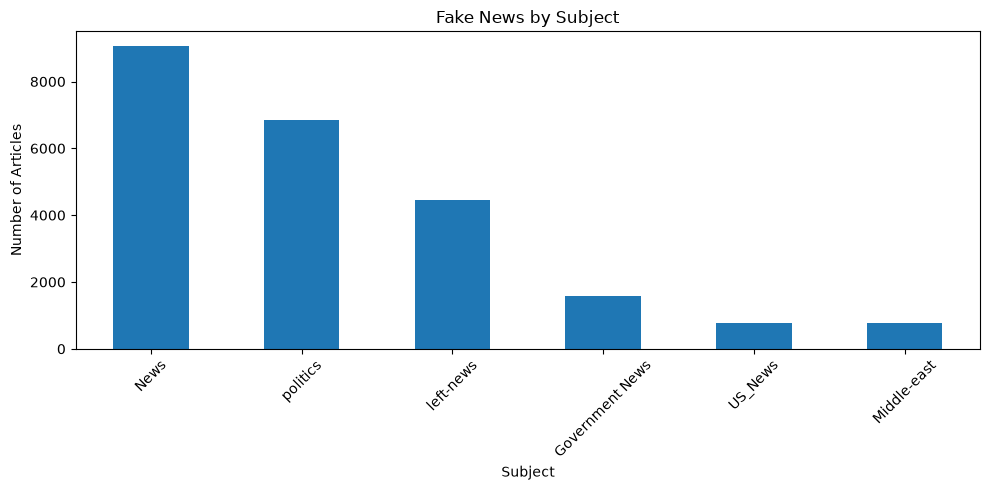

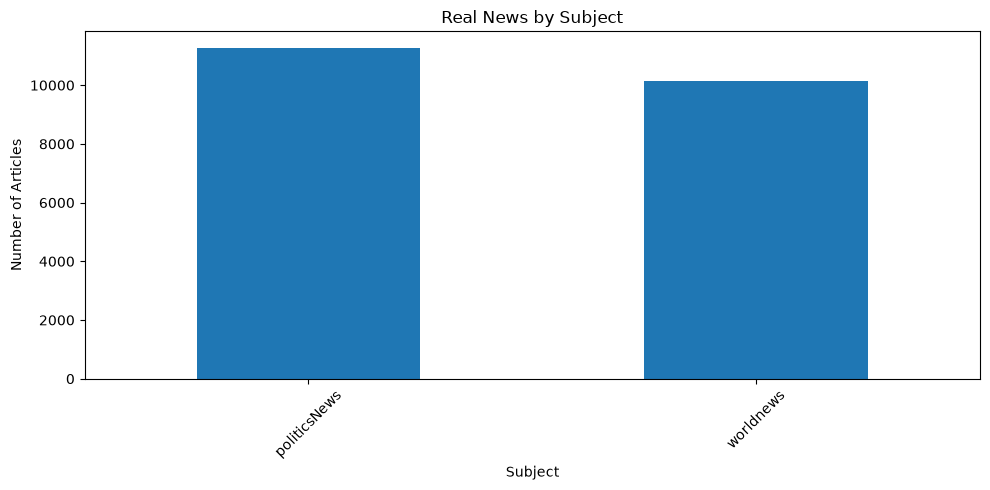

In [ ]:
print("Fake News Subjects:")
display(fake_df["subject"].value_counts())

print("Real News Subjects:")
display(real_df["subject"].value_counts())

plt.figure(figsize=(10, 5))
fake_df["subject"].value_counts().plot(kind="bar")
plt.title("Fake News by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
real_df["subject"].value_counts().plot(kind="bar")
plt.title("Real News by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Exploratory Data Analysis — Article Length

Article length is calculated as the number of characters in the text. The distribution is visualized to inspect short and long articles.

Fake News Text Length:


count    23481.000000
mean      2547.396235
std       2532.884399
min          1.000000
25%       1433.000000
50%       2166.000000
75%       3032.000000
max      51794.000000
Name: text_length, dtype: float64

Real News Text Length:


count    21417.000000
mean      2383.278517
std       1684.835730
min          1.000000
25%        914.000000
50%       2222.000000
75%       3237.000000
max      29781.000000
Name: text_length, dtype: float64

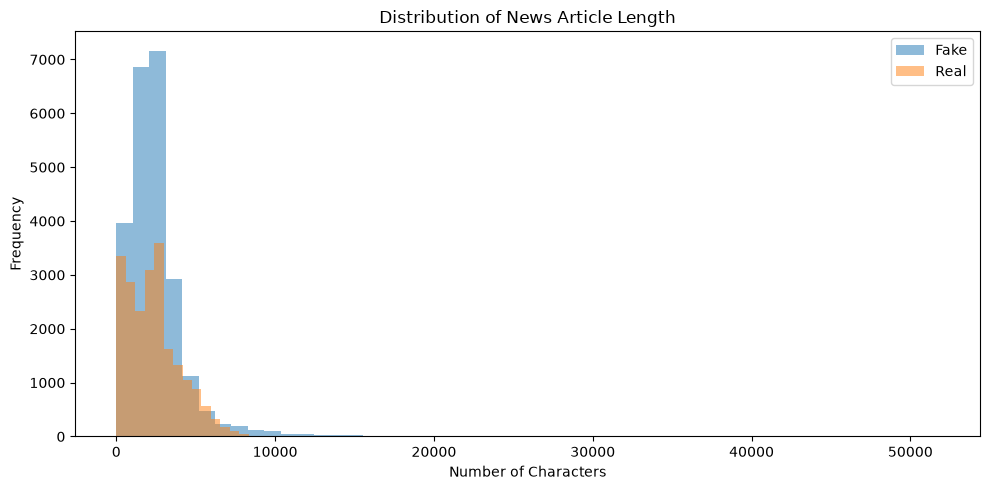

In [ ]:
fake_df["text_length"] = fake_df["text"].fillna("").astype(str).str.len()
real_df["text_length"] = real_df["text"].fillna("").astype(str).str.len()

print("Fake News Text Length:")
display(fake_df["text_length"].describe())

print("Real News Text Length:")
display(real_df["text_length"].describe())

plt.figure(figsize=(10, 5))
plt.hist(fake_df["text_length"], bins=50, alpha=0.5, label="Fake")
plt.hist(real_df["text_length"], bins=50, alpha=0.5, label="Real")
plt.title("Distribution of News Article Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## Create Target Labels and Combine the Datasets

The target variable is:
- `0` → Fake News
- `1` → Real News

The datasets are then combined into one DataFrame.

Combined Dataset Shape: (44898, 6)

Class Distribution:
label
0    23481
1    21417
Name: count, dtype: int64


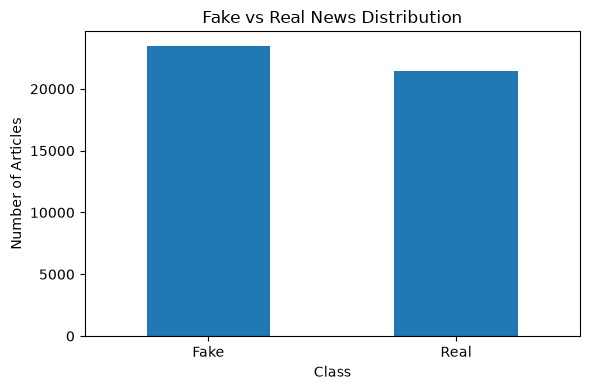

In [ ]:
fake_df["label"] = 0
real_df["label"] = 1

news_df = pd.concat([fake_df, real_df], ignore_index=True)

print("Combined Dataset Shape:", news_df.shape)
print("\nClass Distribution:")
print(news_df["label"].value_counts())

plt.figure(figsize=(6, 4))
news_df["label"].value_counts().plot(kind="bar")
plt.title("Fake vs Real News Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ["Fake", "Real"], rotation=0)
plt.tight_layout()
plt.show()

##  Create a Working Copy

A copy is created so cleaning operations do not modify the original combined dataset.

In [ ]:
clean_df = news_df.copy()
print("Original shape:", news_df.shape)
print("Working dataset shape:", clean_df.shape)
display(clean_df.head())

Original shape: (44898, 6)
Working dataset shape: (44898, 6)


,title,text,subject,date,text_length,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",2893,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1898,0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",3597,0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",2774,0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",2346,0


##  Remove Duplicate Records

Duplicate rows can cause repeated examples and overly optimistic evaluation. They are identified and removed before modeling.

In [ ]:
duplicate_count = clean_df.duplicated().sum()
print("Duplicate rows before removal:", duplicate_count)

if duplicate_count > 0:
    clean_df = clean_df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", clean_df.shape)
print("Remaining duplicate rows:", clean_df.duplicated().sum())

Duplicate rows before removal: 209
Shape after duplicate removal: (44689, 6)
Remaining duplicate rows: 0


##  Check Missing and Empty Values

Null values and empty/whitespace-only values are checked separately. The text field is the primary input feature for classification.

In [ ]:
print("Missing values:")
display(clean_df.isnull().sum())

empty_summary = pd.Series({
    "Empty title": (clean_df["title"].fillna("").astype(str).str.strip() == "").sum(),
    "Empty text": (clean_df["text"].fillna("").astype(str).str.strip() == "").sum(),
    "Empty subject": (clean_df["subject"].fillna("").astype(str).str.strip() == "").sum()
})

print("Empty/whitespace-only values:")
display(empty_summary)

Missing values:


title          0
text           0
subject        0
date           0
text_length    0
label          0
dtype: int64

Empty/whitespace-only values:


Empty title        0
Empty text       631
Empty subject      0
dtype: int64

##  Remove Records with Empty Text

Articles without meaningful text cannot provide useful information to the text classifier, so they are removed.

In [ ]:
empty_text_mask = clean_df["text"].fillna("").astype(str).str.strip() == ""
print("Records with empty text:", empty_text_mask.sum())

clean_df = clean_df.loc[~empty_text_mask].reset_index(drop=True)

print("Shape after removing empty text:", clean_df.shape)
print("Remaining empty text:",
      (clean_df["text"].fillna("").astype(str).str.strip() == "").sum())

Records with empty text: 631
Shape after removing empty text: (44058, 6)
Remaining empty text: 0


## Validate Labels and  Text-Length Anomalies

The target is checked to ensure only the expected classes exist. Very short and long articles are inspected rather than automatically removed because length alone does not prove that an article is invalid.

In [ ]:
print("Unique labels:", sorted(clean_df["label"].unique()))
print("\nLabel counts:")
print(clean_df["label"].value_counts())

clean_df["text_length"] = clean_df["text"].astype(str).str.len()

print("\nShortest articles:")
display(clean_df.nsmallest(5, "text_length")[["title", "text_length", "label"]])

print("\nLongest articles:")
display(clean_df.nlargest(5, "text_length")[["title", "text_length", "label"]])

Unique labels: [np.int64(0), np.int64(1)]

Label counts:
label
0    22848
1    21210
Name: count, dtype: int64

Shortest articles:


,title,text_length,label
12099,DEAR DEMOCRATS AND LIBERALS…Stop Complaining A...,5,0
19005,DEAR DEMOCRATS AND LIBERALS…Stop Complaining A...,5,0
11114,MY FAVORITE EXCUSES…Featuring Hillary Rotten C...,6,0
11445,MULTI-MILLIONAIRE Global-Warming Hypocrites LE...,6,0
11583,ARROGANT ILLEGAL ALIEN Who Voted 5 Times In 20...,6,0



Longest articles:


,title,text_length,label
21670,MEDIA TRIPWIRE? Ping Pong Pizza Conspiracy Pro...,51794,0
22453,MEDIA TRIPWIRE? Ping Pong Pizza Conspiracy Pro...,51794,0
9731,ANTI-AMERICAN GEORGE SOROS Locks Arms With NFL...,49705,0
17366,ANTI-AMERICAN GEORGE SOROS Locks Arms With NFL...,49705,0
21345,The Las Vegas Mass Shooting – More to the Stor...,48835,0


##  Text Preprocessing Function

The same deterministic cleaning function is used for training text and unseen text.

Steps:
1. lowercase text
2. remove HTML tags
3. remove URLs
4. remove punctuation
5. remove numbers
6. normalize whitespace

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

##  Test the Text-Cleaning Function

A sample article is displayed before and after cleaning to verify the preprocessing function.

In [ ]:
sample_text = clean_df["text"].iloc[0]

print("ORIGINAL TEXT:")
print(sample_text[:1000])

print("\n" + "=" * 80)

print("CLEANED TEXT:")
print(clean_text(sample_text)[:1000])

ORIGINAL TEXT:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this despicable, petty, infantile gibberish? Only Trump! His lack of de

##  Apply Text Preprocessing

A separate `clean_text` column is created while retaining the original `text` column for reference.

In [ ]:
clean_df["clean_text"] = clean_df["text"].apply(clean_text)
display(clean_df[["text", "clean_text"]].head())

,text,clean_text
0,Donald Trump just couldn t wish all Americans ...,donald trump just couldn t wish all americans ...
1,House Intelligence Committee Chairman Devin Nu...,house intelligence committee chairman devin nu...
2,"On Friday, it was revealed that former Milwauk...",on friday it was revealed that former milwauke...
3,"On Christmas day, Donald Trump announced that ...",on christmas day donald trump announced that h...
4,Pope Francis used his annual Christmas Day mes...,pope francis used his annual christmas day mes...


##  Remove Text That Becomes Empty After Cleaning

Some records may become empty after preprocessing. Such records are removed because they contain no usable text features.

In [ ]:
empty_clean_mask = clean_df["clean_text"].str.strip() == ""
print("Empty cleaned-text records:", empty_clean_mask.sum())

if empty_clean_mask.any():
    display(clean_df.loc[
        empty_clean_mask, ["title", "text", "subject", "label"]
    ].head(10))
    clean_df = clean_df.loc[~empty_clean_mask].reset_index(drop=True)

clean_df["clean_text_length"] = clean_df["clean_text"].str.len()

print("Shape after cleaned-text validation:", clean_df.shape)
print("Remaining empty cleaned text:",
      (clean_df["clean_text"].str.strip() == "").sum())

Empty cleaned-text records: 84


,title,text,subject,label
9358,https://100percentfedup.com/served-roy-moore-v...,https://100percentfedup.com/served-roy-moore-v...,politics,0
11242,MELANIA TRUMP GIVES POWERFUL SPEECH to Honor ‘...,https://www.youtube.com/watch?v=cJZFepSvxzM,politics,0
11272,TERRORISM EXPERT SEBASTIAN GORKA On What Next ...,https://www.youtube.com/watch?v=-7Tn4gi_Os8,politics,0
11274,TRUMP CABINET MEMBER MICK MULVANEY ON DC: “Thi...,https://www.youtube.com/watch?time_continue=2&...,politics,0
11290,CRYBABY NANCY PELOSI Taunts Trump On Healthcar...,https://www.youtube.com/watch?v=SH0pRtK9sAE,politics,0
11291,SARA CARTER AND JAY SEKULOW With The Latest On...,https://www.youtube.com/watch?v=DRLVvYzG46w,politics,0
11300,SARA CARTER WAS RIGHT ABOUT SPYING ON TRUMP! “...,https://www.youtube.com/watch?v=Ws5ojb0PCCo,politics,0
11346,LIBERAL BIGOT Destroyed by Legendary Democrat ...,https://www.youtube.com/watch?v=P-TBfkqk7gU,politics,0
11380,JUDGE JEANINE PIRRO’S TRUTH BOMB On Fired US A...,https://www.youtube.com/watch?v=yRXmFmgoPTk,politics,0
11425,Judge Jeanine Gets to The Bottom of “Towergate...,https://www.youtube.com/watch?v=n9tfNMQpYWU,politics,0


Shape after cleaned-text validation: (43974, 8)
Remaining empty cleaned text: 0


##  Optional Date Quality Check

The date column is inspected for parsing quality. Date-derived features are not used in the initial text classifier, so the repeated date-processing section from the original implementation has been removed.

In [ ]:
date_parsed = pd.to_datetime(clean_df["date"], format="mixed", errors="coerce")

print("Unparsed dates:", date_parsed.isna().sum())
display(pd.DataFrame({
    "original_date": clean_df["date"].head(10),
    "parsed_date": date_parsed.head(10)
}))

Unparsed dates: 1


,original_date,parsed_date
0,"December 31, 2017",2017-12-31
1,"December 31, 2017",2017-12-31
2,"December 30, 2017",2017-12-30
3,"December 29, 2017",2017-12-29
4,"December 25, 2017",2017-12-25
5,"December 25, 2017",2017-12-25
6,"December 23, 2017",2017-12-23
7,"December 23, 2017",2017-12-23
8,"December 22, 2017",2017-12-22
9,"December 21, 2017",2017-12-21


##  Prepare and Save the Final Modeling Dataset

Only the required columns are retained. The current model uses `clean_text` as the input and `label` as the target.

In [ ]:
model_df = clean_df[
    ["title", "text", "subject", "date", "clean_text", "label"]
].copy()

print("Model dataset shape:", model_df.shape)

print("\nMissing values:")
display(model_df.isnull().sum())

print("\nDuplicate rows:", model_df.duplicated().sum())
print("\nEmpty cleaned text:",
      (model_df["clean_text"].str.strip() == "").sum())
print("\nLabels:")
print(model_df["label"].value_counts())

processed_path = "C:\\Users\\bhumi\\OneDrive\\Desktop\\fake-real-news-detection\\data\\processed\\cleaned_news.csv"
model_df.to_csv(processed_path, index=False)

print("\nCleaned dataset saved:", os.path.exists(processed_path))

Model dataset shape: (43974, 6)

Missing values:


title         0
text          0
subject       0
date          0
clean_text    0
label         0
dtype: int64


Duplicate rows: 0

Empty cleaned text: 0

Labels:
label
0    22764
1    21210
Name: count, dtype: int64

Cleaned dataset saved: True


##  Define Features and Target

The cleaned article text is the input feature `X`, and the binary label is the target `y`.

In [ ]:
X = model_df["clean_text"]
y = model_df["label"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

Input feature shape: (43974,)
Target shape: (43974,)


## Split the Dataset into Training and Testing Sets

An 80/20 stratified split is used. The test set is kept unseen during training and hyperparameter tuning.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting class percentages:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training samples: 35179
Testing samples: 8795

Training class percentages:
label
0    51.77
1    48.23
Name: proportion, dtype: float64

Testing class percentages:
label
0    51.77
1    48.23
Name: proportion, dtype: float64


##  TF-IDF Feature Extraction

TF-IDF converts text into numerical features.

**Important:** the vectorizer is fitted only on `X_train`. `X_test` is transformed using the already-fitted vectorizer, preventing test-set vocabulary/IDF leakage.

In [ ]:
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (35179, 50000)
Testing TF-IDF shape: (8795, 50000)
Number of TF-IDF features: 50000


##  Train and Evaluate Logistic Regression

Logistic Regression provides a strong linear baseline for high-dimensional TF-IDF text features.

In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=["Fake", "Real"]))

Accuracy : 0.9927231381466742
Precision: 0.9908364661654135
Recall   : 0.9941065535124941
F1 Score : 0.9924688161920452

Classification Report:
              precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      4553
        Real       0.99      0.99      0.99      4242

    accuracy                           0.99      8795
   macro avg       0.99      0.99      0.99      8795
weighted avg       0.99      0.99      0.99      8795



## Train and Evaluate Multinomial Naive Bayes

Multinomial Naive Bayes is a standard text-classification baseline and provides a useful comparison with the linear models.

In [ ]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall   :", recall_score(y_test, y_pred_nb))
print("F1 Score :", f1_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, target_names=["Fake", "Real"]))

Accuracy : 0.9564525298465036
Precision: 0.9551781080443501
Recall   : 0.9545025931164545
F1 Score : 0.9548402311048225

Classification Report:
              precision    recall  f1-score   support

        Fake       0.96      0.96      0.96      4553
        Real       0.96      0.95      0.95      4242

    accuracy                           0.96      8795
   macro avg       0.96      0.96      0.96      8795
weighted avg       0.96      0.96      0.96      8795



##  Train and Evaluate Linear SVM

Linear SVM is well suited to sparse, high-dimensional TF-IDF representations and is included as a strong text-classification candidate.

In [ ]:
svm_model = LinearSVC(C=1.0, random_state=42)
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall   :", recall_score(y_test, y_pred_svm))
print("F1 Score :", f1_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, target_names=["Fake", "Real"]))

Accuracy : 0.9965889710062535
Precision: 0.9962299717247879
Recall   : 0.9966996699669967
F1 Score : 0.9964647654961113

Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4553
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



## Compare the Initial Models

Accuracy, precision, recall, and F1-score are compared. The model with the strongest overall performance is selected for further tuning.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_svm)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_svm)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_svm)
    ]
})

display(results.sort_values("F1 Score", ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.996589,0.996230,0.996700,0.996465
1,Logistic Regression,0.992723,0.990836,0.994107,0.992469
2,Multinomial Naive Bayes,0.956453,0.955178,0.954503,0.954840


##  Hyperparameter Tuning — Linear SVM

Linear SVM is tuned using 5-fold cross-validation. Only the training data is used during tuning; the held-out test set remains untouched.

The regularization parameter `C` is optimized using F1-score.

In [ ]:
param_grid = {"C": [0.01, 0.1, 1, 10]}

svm_tuning = GridSearchCV(
    estimator=LinearSVC(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

svm_tuning.fit(X_train_tfidf, y_train)

print("Best parameters:", svm_tuning.best_params_)
print("Best cross-validation F1 score:", svm_tuning.best_score_)

tuning_results = pd.DataFrame(svm_tuning.cv_results_)
display(
    tuning_results[
        ["param_C", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 10}
Best cross-validation F1 score: 0.9963783811391764


,param_C,mean_test_score,std_test_score,rank_test_score
3,10.00,0.996378,0.000462,1
2,1.00,0.996083,0.000442,2
1,0.10,0.992642,0.000922,3
0,0.01,0.975971,0.000823,4


##  Evaluate the Tuned Linear SVM

The best estimator found during cross-validation is evaluated on the held-out test set to obtain the final test performance.

In [ ]:
best_svm = svm_tuning.best_estimator_
y_pred_best_svm = best_svm.predict(X_test_tfidf)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_best_svm),
    "Precision": precision_score(y_test, y_pred_best_svm),
    "Recall": recall_score(y_test, y_pred_best_svm),
    "F1 Score": f1_score(y_test, y_pred_best_svm)
}

print("Tuned Linear SVM Results")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_best_svm, target_names=["Fake", "Real"]
))

Tuned Linear SVM Results
Accuracy: 0.997157
Precision: 0.996702
Recall: 0.997407
F1 Score: 0.997054

Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4553
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



##  Final Confusion Matrix

The confusion matrix shows correct and incorrect predictions for Fake and Real news.

Final Confusion Matrix:
[[4539   14]
 [  11 4231]]


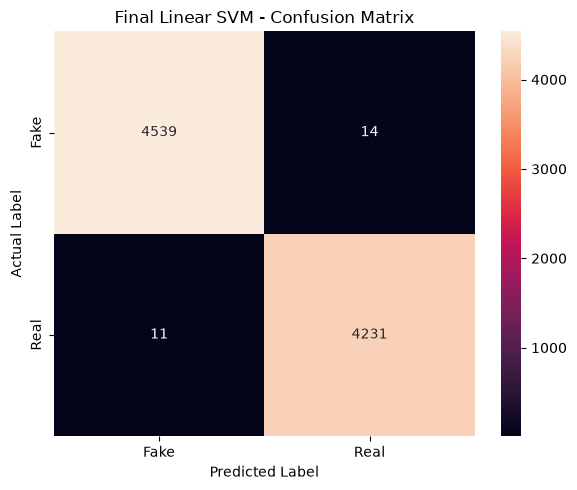

In [ ]:
cm_final = confusion_matrix(y_test, y_pred_best_svm)
print("Final Confusion Matrix:")
print(cm_final)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final Linear SVM - Confusion Matrix")
plt.tight_layout()
plt.show()

##  Compare Original and Tuned Linear SVM

This comparison shows whether hyperparameter tuning improved the original Linear SVM.

In [ ]:
comparison = pd.DataFrame({
    "Version": ["Original Linear SVM", "Tuned Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_best_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_best_svm)
    ],
    "Recall": [
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_best_svm)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_best_svm)
    ]
})

display(comparison)

,Version,Accuracy,Precision,Recall,F1 Score
0,Original Linear SVM,0.996589,0.996230,0.996700,0.996465
1,Tuned Linear SVM,0.997157,0.996702,0.997407,0.997054


##  Save the Final Model and TF-IDF Vectorizer

The tuned SVM and fitted TF-IDF vectorizer are saved so they can be reused without retraining.

In [ ]:
model_path = "C:\\Users\\bhumi\\OneDrive\\Desktop\\fake-real-news-detection\\models\\final_svm_model.pkl"
vectorizer_path = "C:\\Users\\bhumi\\OneDrive\\Desktop\\fake-real-news-detection\\models\\tfidf_vectorizer.pkl"

joblib.dump(best_svm, model_path)
joblib.dump(tfidf, vectorizer_path)

print("SVM model saved:", os.path.exists(model_path))
print("TF-IDF vectorizer saved:", os.path.exists(vectorizer_path))

print("\nFinal Model: Tuned Linear SVM")
print("Best C:", svm_tuning.best_params_["C"])
print("CV F1 Score:", svm_tuning.best_score_)
print("Test Accuracy:", final_metrics["Accuracy"])
print("Test Precision:", final_metrics["Precision"])
print("Test Recall:", final_metrics["Recall"])
print("Test F1 Score:", final_metrics["F1 Score"])

SVM model saved: True
TF-IDF vectorizer saved: True

Final Model: Tuned Linear SVM
Best C: 10
CV F1 Score: 0.9963783811391764
Test Accuracy: 0.9971574758385446
Test Precision: 0.9967020023557126
Test Recall: 0.9974068835454974
Test F1 Score: 0.9970543183692706


## Load the Saved Model and Vectorizer

The saved artifacts are loaded to verify that the prediction stage works from persisted files.

In [ ]:
loaded_model = joblib.load(model_path)
loaded_tfidf = joblib.load(vectorizer_path)

print("Model and TF-IDF vectorizer loaded successfully.")

Model and TF-IDF vectorizer loaded successfully.


##  Define a Reusable Prediction Function

New text is cleaned using the same preprocessing function, transformed using the fitted TF-IDF vectorizer, and classified by the saved SVM.

The SVM decision score indicates the position relative to the classification boundary; it is **not a calibrated probability**.

In [ ]:
def predict_news(news_text):
    cleaned_text = clean_text(news_text)

    if not cleaned_text.strip():
        raise ValueError("The supplied news text is empty after preprocessing.")

    text_vector = loaded_tfidf.transform([cleaned_text])
    prediction = loaded_model.predict(text_vector)[0]
    decision_score = loaded_model.decision_function(text_vector)[0]

    label = "Fake News" if prediction == 0 else "Real News"
    return label, decision_score

##  Prediction on Unseen News — Example 1

A previously unseen article is passed through the saved preprocessing, vectorization, and prediction pipeline.

In [ ]:
unseen_news_1 = """
The government announced a new national education initiative today,
providing additional funding to schools and universities. Officials said
the program will focus on improving digital learning, teacher training,
and access to educational resources.
"""

label_1, score_1 = predict_news(unseen_news_1)

print("Prediction:", label_1)
print("Decision Score:", score_1)

Prediction: Fake News
Decision Score: -0.8466205615688024


##  Prediction on Unseen News — Example 2

A second unseen article is tested using the same reusable prediction function.

In [ ]:
unseen_news_2 = """
Scientists at the university published the results of a new study after
conducting experiments over several months. The researchers said the
findings will require further independent verification.
"""

label_2, score_2 = predict_news(unseen_news_2)

print("Prediction:", label_2)
print("Decision Score:", score_2)

Prediction: Fake News
Decision Score: -0.38967945096844436


## Final Conclusion

This notebook completes the end-to-end Fake/Real News classification workflow:

- data loading and understanding
- exploratory data analysis
- duplicate and empty-text handling
- text preprocessing
- stratified train-test splitting
- leakage-safe TF-IDF extraction
- multiple ML models
- model evaluation and comparison
- Linear SVM hyperparameter tuning
- final test-set evaluation
- confusion-matrix analysis
- model/vectorizer persistence
- unseen-news prediction

The tuned Linear SVM is selected as the final model based on the evaluation performed in this notebook.